In [1]:
import sys
from pathlib import Path

package_root = str(Path.cwd().parent)
if package_root not in sys.path:
    sys.path.append(package_root)

In [2]:
from __future__ import annotations
import pandas as pd 
from typing import Dict, List, Tuple
from pathlib import Path
from collections.abc import Iterable
import matplotlib.pyplot as plt
import seaborn as sns
import os 
import time
import re
import numpy as np
from copy import deepcopy
from datetime import datetime
from typing import Any
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

In [3]:
pd.set_option("display.max_colwidth", None)

In [4]:
DATASET_FOLDER = "../../../dataset/processed-data"
DEVICE_MAPPING_FOLDER = DATASET_FOLDER + "/device-mapping"
INPUT_FOLDER = DATASET_FOLDER + "/input-data"
DATASET1 = "dataset1"
DATASET2 = "dataset2"

In [5]:
MAPPING_LIST_1 = f"{DEVICE_MAPPING_FOLDER}/{DATASET1}/list_of_devices_processed.csv"
MAPPING_LIST_2 = f"{DEVICE_MAPPING_FOLDER}/{DATASET2}/list_of_devices_processed.csv"
INPUT_1 = f"{INPUT_FOLDER}/{DATASET1}"
INPUT_2 = f"{INPUT_FOLDER}/{DATASET2}"

In [6]:
csv_files_1 = [f"{INPUT_1}/{f.name}" for f in sorted(Path(INPUT_1).iterdir()) if f.is_file() and f.suffix == ".csv"]
for file in csv_files_1:
    print(file)

../../../dataset/processed-data/input-data/dataset1/16-09-23.csv
../../../dataset/processed-data/input-data/dataset1/16-09-24.csv
../../../dataset/processed-data/input-data/dataset1/16-09-25.csv
../../../dataset/processed-data/input-data/dataset1/16-09-26.csv
../../../dataset/processed-data/input-data/dataset1/16-09-27.csv
../../../dataset/processed-data/input-data/dataset1/16-09-28.csv
../../../dataset/processed-data/input-data/dataset1/16-09-29.csv
../../../dataset/processed-data/input-data/dataset1/16-09-30.csv
../../../dataset/processed-data/input-data/dataset1/16-10-01.csv
../../../dataset/processed-data/input-data/dataset1/16-10-02.csv
../../../dataset/processed-data/input-data/dataset1/16-10-03.csv
../../../dataset/processed-data/input-data/dataset1/16-10-04.csv
../../../dataset/processed-data/input-data/dataset1/16-10-05.csv
../../../dataset/processed-data/input-data/dataset1/16-10-06.csv
../../../dataset/processed-data/input-data/dataset1/16-10-07.csv
../../../dataset/processe

In [7]:
device_mapping_1 = pd.read_csv(MAPPING_LIST_1)
device_dict_1 = (
    device_mapping_1
    .set_index("mac_address")
    .drop(columns=["mac_address"], errors="ignore")
    .to_dict(orient="index")
)
device_dict_1

{'d0:52:a8:00:67:5e': {'device_name': 'Smart Things',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'hub',
  'vendor': 'Samsung SmartThings'},
 '44:65:0d:56:cc:d3': {'device_name': 'Amazon Echo',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'smart speaker',
  'vendor': 'Amazon'},
 '70:ee:50:18:34:43': {'device_name': 'Netatmo Welcome',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Netatmo'},
 'f4:f2:6d:93:51:f1': {'device_name': 'TP-Link Day Night Cloud camera',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'TP-Link'},
 '00:16:6c:ab:6b:88': {'device_name': 'Samsung SmartCam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Samsung'},
 '30:8c:fb:2f:e4:b2': {'device_name': 'Dropcam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Dropcam'},
 '00:62:6e:51:27:2e': {'device_name': 'Insteon Camera Wired',
  'ip_address': 

In [8]:
FEATURE_COLUMNS = [
    "packet_count",
    "total_bytes",
]

DEVICE_COLUMN = "eth.src"          # Replace with "eth.src" if applicable
TIME_COLUMN = "timestamp"
LABEL_COLUMN = "is_iot_device"

KPLITS = 5
RANDOM_STATE = 42
WINDOW_SECONDS = 4

- Last time, I was using "active window" only, while I should have used all window
- For function `extract_data_from_pcap`, I have to filter traffics containing any MAC addresses which are not in the ground truth list of devices. 

In [9]:
# Outgoing volume
def extract_data_from_pcap(
    file_paths: Iterable[str], 
    device_mapping_list: Dict[str, Dict[str,str]]
) -> pd.DataFrame:
    columns = [
        "frame.time_epoch",
        "frame.len",
        "eth.src",
    ]

    all_data = []

    for file_path in file_paths:
        raw_df = pd.read_csv(
            file_path,
            usecols=columns,
            dtype={
                "frame.time_epoch": "float64",
                "frame.len": "int32",
                "eth.src": "category",
            }
        )

        raw_df["capture_id"] = Path(file_path).stem
        all_data.append(raw_df)


    res = pd.concat(all_data, ignore_index=True)
    res = res.sort_values(
        ["frame.time_epoch", "eth.src"],
        ignore_index=True,
    )

    return res


In [10]:
all_data = extract_data_from_pcap(csv_files_1, device_dict_1)

In [11]:
all_data.head(10)

,frame.time_epoch,frame.len,eth.src,capture_id
0,1.474553e+09,70,18:b7:9e:02:20:44,16-09-23
1,1.474553e+09,66,18:b7:9e:02:20:44,16-09-23
2,1.474553e+09,66,14:cc:20:51:33:ea,16-09-23
3,1.474553e+09,60,d0:52:a8:00:67:5e,16-09-23
4,1.474553e+09,98,14:cc:20:51:33:ea,16-09-23
5,1.474553e+09,88,70:ee:50:18:34:43,16-09-23
6,1.474553e+09,68,14:cc:20:51:33:ea,16-09-23
7,1.474553e+09,54,14:cc:20:51:33:ea,16-09-23
8,1.474553e+09,42,ec:1a:59:79:f4:89,16-09-23
9,1.474553e+09,42,14:cc:20:51:33:ea,16-09-23


In [12]:
trace_duration = (
    all_data.groupby("capture_id")["frame.time_epoch"]
    .agg(start_time="min", end_time="max")
    .reset_index()
)

trace_duration["duration_seconds"] = (
    trace_duration["end_time"] - trace_duration["start_time"]
)

trace_duration["duration_minutes"] = (
    trace_duration["duration_seconds"] / 60
)

trace_duration["duration_hours"] = (
    trace_duration["duration_seconds"] / 3600
)

trace_duration

,capture_id,start_time,end_time,duration_seconds,duration_minutes,duration_hours
0,16-09-23,1.474553e+09,1.474639e+09,86397.728747,1439.962146,23.999369
1,16-09-24,1.474639e+09,1.474726e+09,86396.995232,1439.949921,23.999165
2,16-09-25,1.474726e+09,1.474812e+09,86397.322154,1439.955369,23.999256
3,16-09-26,1.474812e+09,1.474898e+09,86398.748936,1439.979149,23.999652
4,16-09-27,1.474898e+09,1.474985e+09,86399.490630,1439.991510,23.999859
5,16-09-28,1.474985e+09,1.475071e+09,86398.740564,1439.979009,23.999650
6,16-09-29,1.475071e+09,1.475158e+09,86397.974485,1439.966241,23.999437
7,16-09-30,1.475158e+09,1.475244e+09,86397.994338,1439.966572,23.999443
8,16-10-01,1.475244e+09,1.475330e+09,86397.621072,1439.960351,23.999339
9,16-10-02,1.475330e+09,1.475413e+09,82797.927161,1379.965453,22.999424


- There is barely a set of devices that exist in multiple capture file. 

# Re-EDA

In [13]:
def label_features(
    features: pd.DataFrame,
    device_mapping: Dict[str, Dict[str, str]]
) -> pd.DataFrame:

    unknown_macs = set(features["eth.src"]) - set(device_mapping)

    if unknown_macs:
        raise KeyError(
            f"MAC addresses not found in device_mapping: {unknown_macs}"
        )

    res = features.copy()
    res["is_iot_device"] = res["eth.src"].map(
        lambda x: device_mapping[x]["is_iot_device"]
    )
    res["device_type"] = res["eth.src"].map(
        lambda x: device_mapping[x]["device_type"]
    )
    res["vendor"] = res["eth.src"].map(
        lambda x: device_mapping[x]["vendor"]
    )

    return res

In [14]:
eda_df = all_data.copy()

In [15]:
result = (
    eda_df.groupby("eth.src", observed=True)["capture_id"]
      .unique()
      .reset_index()
)
result

,eth.src,capture_id
0,00:16:6c:ab:6b:88,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
1,00:24:e4:10:ee:4c,[16-10-07]
2,00:24:e4:11:18:a8,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07]"
3,00:24:e4:1b:6f:96,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
4,00:24:e4:20:28:c6,"[16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
5,00:62:6e:51:27:2e,"[16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
6,08:21:ef:3b:fc:e3,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
7,14:cc:20:51:33:ea,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
8,18:b4:30:25:be:e4,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11]"
9,18:b7:9e:02:20:44,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"


In [16]:
capture_counts = (
    eda_df.groupby("eth.src")["capture_id"]
      .nunique()
)

single_capture_devices = capture_counts[
    capture_counts == 1
].index

single_capture_info = (
    eda_df[eda_df["eth.src"].isin(single_capture_devices)]
    [
        ["eth.src"]
    ]
    .drop_duplicates()
    .sort_values("eth.src")
)
# single_capture_info = label_features(single_capture_info, device_dict_1)
# single_capture_info_with_label = label_features(single_capture_info, device_dict_1)
# single_capture_info
eth_src_list = single_capture_info["eth.src"].dropna().unique().tolist()
print(f"Number of devices seen in only one capture: {len(eth_src_list)}")
for mac in eth_src_list:
    if mac in device_dict_1:
        print(f"mac '{mac}': {device_dict_1[mac]['device_name']}")
    else:
        print(f"mac '{mac}': not found in device list")

Number of devices seen in only one capture: 6
mac '00:24:e4:10:ee:4c': not found in device list
mac '30:8c:fb:b6:ea:45': Nest Dropcam
mac '8a:05:81:fa:cc:14': not found in device list
mac 'd2:13:91:23:2a:58': not found in device list
mac 'e8:ab:fa:19:de:4f': Insteon Camera Wireless
mac 'f4:5c:89:93:cc:85': MacBook/Iphone


- We have to filter out device with only one capture_id as it can't be splitted in training and validation without data leakage

In [17]:
# exclude_devices = ["00:24:e4:1b:6f:96", "18:b4:30:25:be:e4", "74:6a:89:00:2e:25"]
exclude_devices = []

# camera_devices = ["70:ee:50:18:34:43","30:8c:fb:2f:e4:b2","00:16:6c:ab:6b:88","f4:f2:6d:93:51:f1","00:62:6e:51:27:2e"]
camera_devices = []
hub = ["d0:52:a8:00:67:5e","44:65:0d:56:cc:d3"]

gateway = "14:cc:20:51:33:ea"
exclude_devices.extend(camera_devices)
exclude_devices.append(gateway)
exclude_devices.extend(hub)

"""
mac '70:ee:50:18:34:43': Netatmo Welcome,	is_iot: 1, 	device_type: camera
mac '30:8c:fb:2f:e4:b2': Dropcam,	is_iot: 1, 	device_type: camera
mac '00:16:6c:ab:6b:88': Samsung SmartCam,	is_iot: 1, 	device_type: camera
mac 'f4:f2:6d:93:51:f1': TP-Link Day Night Cloud camera,	is_iot: 1, 	device_type: camera
mac '00:62:6e:51:27:2e': Insteon Camera,	is_iot: 1, 	device_type: camera
"""
# exclude_devices = []
exclude_devices.extend(single_capture_info["eth.src"].to_list())
exclude_devices

['14:cc:20:51:33:ea',
 'd0:52:a8:00:67:5e',
 '44:65:0d:56:cc:d3',
 '00:24:e4:10:ee:4c',
 '30:8c:fb:b6:ea:45',
 '8a:05:81:fa:cc:14',
 'd2:13:91:23:2a:58',
 'e8:ab:fa:19:de:4f',
 'f4:5c:89:93:cc:85']

In [18]:
device_to_be_include = set(device_dict_1) - set(exclude_devices)
len(device_to_be_include)

25

In [19]:
# process_df = all_data[~all_data["eth.src"].isin(exclude_devices)].copy()
# process_df = all_data[all_data["eth.src"].isin(device_to_be_include)].copy()
process_df = all_data.copy()

In [20]:
# list_of_devices_to_be_classified = process_df["eth.src"].unique().tolist()
list_of_devices_to_be_classified = list(device_to_be_include)
print(f"Total: {len(list_of_devices_to_be_classified)} devices")
for mac in list_of_devices_to_be_classified:
    print(f"mac '{mac}': {device_dict_1[mac]["device_name"]},\tis_iot: {device_dict_1[mac]["is_iot_device"]}, \tdevice_type: {device_dict_1[mac]["device_type"]}")

Total: 25 devices
mac 'd0:73:d5:01:83:08': Light Bulbs LiFX Smart Bulb,	is_iot: 1, 	device_type: smart bulb
mac '00:24:e4:1b:6f:96': Withings Smart scale,	is_iot: 1, 	device_type: smart scale
mac 'f4:f2:6d:93:51:f1': TP-Link Day Night Cloud camera,	is_iot: 1, 	device_type: camera
mac '18:b4:30:25:be:e4': NEST Protect smoke alarm,	is_iot: 1, 	device_type: smoke alarm
mac '74:6a:89:00:2e:25': Blipcare Blood Pressure meter,	is_iot: 1, 	device_type: blood pressure monitor
mac '08:21:ef:3b:fc:e3': Samsung Galaxy Tab,	is_iot: 0, 	device_type: nan
mac 'ac:bc:32:d4:6f:2f': MacBook,	is_iot: 0, 	device_type: nan
mac 'b4:ce:f6:a7:a3:c2': Android Phone,	is_iot: 0, 	device_type: nan
mac '70:ee:50:18:34:43': Netatmo Welcome,	is_iot: 1, 	device_type: camera
mac 'd0:a6:37:df:a1:e1': IPhone,	is_iot: 0, 	device_type: nan
mac 'ec:1a:59:83:28:11': Belkin wemo motion sensor,	is_iot: 1, 	device_type: motion sensor
mac '40:f3:08:ff:1e:da': Android Phone,	is_iot: 0, 	device_type: nan
mac '00:16:6c:ab:6b:88': 

In [21]:
# Only outgoing feature
def build_feature(raw_df: pd.DataFrame, device_to_be_include: set, window: int = WINDOW_SECONDS) -> pd.DataFrame:
    if window <= 0:
        raise ValueError("window must be greater than 0")

    all_features = []
    df = raw_df.copy()
    for capture_id, capture_df in df.groupby(
        "capture_id",
        sort=False,
        observed=True,
    ):
        capture_df = capture_df.copy()

        # All devices appearing as eth.src in this capture
        devices = capture_df["eth.src"].dropna().unique()

        devices = np.array([
            device
            for device in devices
            if device in device_to_be_include
        ])

        capture_start = capture_df["frame.time_epoch"].min()
        capture_end = capture_df["frame.time_epoch"].max()

        # Assign packets to globally aligned windows for this capture
        capture_df["window"] = (
            (capture_df["frame.time_epoch"] - capture_start) // window
        ).astype("int32")


        # Calculate features where packets actually exist
        features = (
            capture_df[
                capture_df["eth.src"].isin(devices)
            ]
            .groupby(
                ["window", "eth.src"],
                sort=False,
                observed=True,
            )
            .agg(
                packet_count=("frame.len", "size"),
                total_bytes=("frame.len", "sum"),
            )
        )

        # Missing device/window combinations become zero
        features = (
            features
            .reset_index()
        )

        features["capture_id"] = capture_id

        all_features.append(features)

    if not all_features:
        return pd.DataFrame(
            columns=[
                "capture_id",
                "window",
                "eth.src",
                "packet_count",
                "total_bytes",
            ]
        )

    result = pd.concat(
        all_features,
        ignore_index=True,
    )

    result["packet_count"] = result["packet_count"].astype("int64")
    result["total_bytes"] = result["total_bytes"].astype("int64")

    return result[
        [
            "capture_id",
            "window",
            "eth.src",
            "packet_count",
            "total_bytes",
        ]
    ]


In [22]:
features = build_feature(raw_df=process_df, device_to_be_include=device_to_be_include, window=7200)

In [23]:
len(features), len(process_df)

(3465, 23815728)

In [24]:
features.head(5)

,capture_id,window,eth.src,packet_count,total_bytes
0,16-09-23,0,18:b7:9e:02:20:44,419,45104
1,16-09-23,0,70:ee:50:18:34:43,999,67662
2,16-09-23,0,ec:1a:59:79:f4:89,2784,1120051
3,16-09-23,0,30:8c:fb:2f:e4:b2,6883,1061828
4,16-09-23,0,00:24:e4:11:18:a8,1973,155890


In [25]:
labeled_features = label_features(features=features, device_mapping=device_dict_1)

In [26]:
labeled_features.head(10)

,capture_id,window,eth.src,packet_count,total_bytes,is_iot_device,device_type,vendor
0,16-09-23,0,18:b7:9e:02:20:44,419,45104,1,smart speaker,Invoxia
1,16-09-23,0,70:ee:50:18:34:43,999,67662,1,camera,Netatmo
2,16-09-23,0,ec:1a:59:79:f4:89,2784,1120051,1,smart switch,Belkin
3,16-09-23,0,30:8c:fb:2f:e4:b2,6883,1061828,1,camera,Dropcam
4,16-09-23,0,00:24:e4:11:18:a8,1973,155890,1,baby monitor,Withings
5,16-09-23,0,08:21:ef:3b:fc:e3,1687,206830,0,NaN,NaN
6,16-09-23,0,f4:f2:6d:93:51:f1,580,45842,1,camera,TP-Link
7,16-09-23,0,00:16:6c:ab:6b:88,5278,1991428,1,camera,Samsung
8,16-09-23,0,ec:1a:59:83:28:11,3247,315742,1,motion sensor,Belkin
9,16-09-23,0,70:5a:0f:e4:9b:c0,511,44442,1,printer,HP


In [27]:
labeled_features[(labeled_features["packet_count"] == 0) & (labeled_features["total_bytes"] == 0) & (labeled_features["is_iot_device"] == 1)].head(10)

,capture_id,window,eth.src,packet_count,total_bytes,is_iot_device,device_type,vendor


In [28]:
labeled_features[(labeled_features["packet_count"] == 0) & (labeled_features["total_bytes"] == 0) & (labeled_features["is_iot_device"] == 0)]

,capture_id,window,eth.src,packet_count,total_bytes,is_iot_device,device_type,vendor


# Training and evaluation

In [29]:
data_df = labeled_features.copy()

In [30]:
def create_under_sampler(random_seed: int = 42) -> RandomUnderSampler:
    """
    Create a RandomUnderSampler for undersampling the majority class.

    Args:
        random_seed (int): Random seed for reproducibility.

    Returns:
        RandomUnderSampler: An instance of the RandomUnderSampler.
    """
    return RandomUnderSampler(random_state=random_seed)

def create_decision_tree(random_seed: int = 42) -> DecisionTreeClassifier:
    return DecisionTreeClassifier(
        criterion="gini",
        splitter="best",
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        min_weight_fraction_leaf=0.0,
        max_features=None,
        max_leaf_nodes=None,
        min_impurity_decrease=0.0,
        class_weight="balanced",
        random_state=random_seed,
    )

- For this step, we will perform KFold. We will start with have the model trained on every device, then perform validation on those same devices.
- Later on, we will split by device, which means if the device in training set, it should not exist in validation set.

In [31]:
def device_capture_repeated_split(
    df: pd.DataFrame,
    list_of_devices_to_be_classified,
    n_splits: int = 5,
    random_state: int = 42,
):
    target_devices = set(list_of_devices_to_be_classified)

    # ---------------------------------------------------------
    # Rows belonging to devices we want to classify
    # ---------------------------------------------------------
    target_mask = df["eth.src"].isin(target_devices).to_numpy()
    target_positions = np.flatnonzero(target_mask)

    work_df = df.iloc[target_positions][
        ["eth.src", "capture_id"]
    ].copy()

    # ---------------------------------------------------------
    # Validate devices
    # ---------------------------------------------------------
    existing_devices = set(work_df["eth.src"].unique())

    missing_devices = target_devices - existing_devices

    if missing_devices:
        raise ValueError(
            f"Devices not found in dataframe: {missing_devices}"
        )

    # Unique (device, capture) pairs
    device_captures = (
        work_df
        .drop_duplicates()
        .reset_index(drop=True)
    )

    capture_counts = (
        device_captures
        .groupby("eth.src", observed=True)
        .size()
    )

    # A device needs at least 2 captures to have
    # capture-separated train AND validation data.
    insufficient = capture_counts[capture_counts < 2]

    if not insufficient.empty:
        raise ValueError(
            "These devices have fewer than 2 capture_ids, "
            "so capture-level train/validation separation is impossible:\n"
            f"{insufficient}"
        )

    rng = np.random.default_rng(random_state)

    # ---------------------------------------------------------
    # Precompute shuffled capture list for each device
    # ---------------------------------------------------------
    captures_by_device = {}

    for device, group in device_captures.groupby(
        "eth.src",
        observed=True,
        sort=False,
    ):
        captures = group["capture_id"].to_numpy().copy()
        rng.shuffle(captures)

        captures_by_device[device] = captures

    # ---------------------------------------------------------
    # Build repeated splits
    # ---------------------------------------------------------
    folds = []

    row_devices = work_df["eth.src"].to_numpy()
    row_captures = work_df["capture_id"].to_numpy()

    for fold_idx in range(n_splits):

        # Which capture is validation for each device
        val_capture_by_device = {
            device: captures[fold_idx % len(captures)]
            for device, captures in captures_by_device.items()
        }

        # Construct validation mask
        val_mask = np.zeros(
            len(work_df),
            dtype=bool,
        )

        for device, val_capture in val_capture_by_device.items():
            val_mask |= (
                (row_devices == device)
                & (row_captures == val_capture)
            )

        folds.append(
            {
                "fold": fold_idx,
                "train_iloc": target_positions[~val_mask],
                "val_iloc": target_positions[val_mask],
                "val_capture_by_device": val_capture_by_device,
            }
        )

    return folds

In [32]:
training_and_validation_folds = device_capture_repeated_split(
    df=data_df,
    list_of_devices_to_be_classified=list_of_devices_to_be_classified,
    n_splits=KPLITS,
    random_state=RANDOM_STATE
)

- Verify no leakage based on `capture_id`

In [33]:
for fold in training_and_validation_folds:
    train_df = data_df.iloc[fold["train_iloc"]]
    val_df = data_df.iloc[fold["val_iloc"]]
    print(f"Fold {fold["fold"]}:")
    for device in list_of_devices_to_be_classified:
        train_captures = set(
            train_df.loc[
                train_df["eth.src"] == device,
                "capture_id",
            ]
        )

        val_captures = set(
            val_df.loc[
                val_df["eth.src"] == device,
                "capture_id",
            ]
        )
        print(f"\tMac {device}: trained on {train_captures}, validated on {val_captures}")

        assert train_captures.isdisjoint(val_captures)

print("No capture leakage.")

Fold 0:
	Mac d0:73:d5:01:83:08: trained on {'16-10-03', '16-10-02', '16-10-05', '16-10-09', '16-09-30', '16-10-08', '16-10-12', '16-09-29', '16-10-04', '16-10-07', '16-10-06', '16-10-11', '16-09-28', '16-10-01'}, validated on {'16-10-10'}
	Mac 00:24:e4:1b:6f:96: trained on {'16-10-10', '16-09-29', '16-10-04', '16-10-11', '16-09-30', '16-10-12', '16-09-25', '16-09-26', '16-10-06', '16-10-01', '16-10-05', '16-10-09', '16-10-08', '16-10-07', '16-10-03', '16-10-02', '16-09-27', '16-09-24', '16-09-28'}, validated on {'16-09-23'}
	Mac f4:f2:6d:93:51:f1: trained on {'16-10-03', '16-10-02', '16-10-05', '16-09-30', '16-09-23', '16-09-27', '16-09-25', '16-10-04', '16-09-26', '16-09-24', '16-09-28', '16-10-01'}, validated on {'16-09-29'}
	Mac 18:b4:30:25:be:e4: trained on {'16-10-03', '16-10-02', '16-10-05', '16-10-09', '16-10-10', '16-09-23', '16-10-08', '16-09-27', '16-09-25', '16-09-29', '16-10-04', '16-09-26', '16-09-24', '16-10-07', '16-10-06', '16-10-11', '16-09-28', '16-10-01'}, validated 

In [34]:
def evaluate_device_predictions(
        val_df: pd.DataFrame, 
        list_of_devices_to_be_classified: list,
        device_dict: dict
    ) -> Tuple[dict,pd.DataFrame]:
    expected_devices = set(list_of_devices_to_be_classified)
    actual_devices = set(val_df["eth.src"].unique())

    # ---------------------------------------------------------
    # 1. Verify validation contains exactly the expected devices
    # ---------------------------------------------------------
    if actual_devices != expected_devices:
        missing = expected_devices - actual_devices
        unexpected = actual_devices - expected_devices

        raise ValueError(
            f"Device mismatch.\n"
            f"Missing from validation: {missing}\n"
            f"Unexpected in validation: {unexpected}"
        )

    prediction_values = set(
        val_df["prediction_each_window"].unique()
    )

    if not prediction_values.issubset({0, 1}):
        raise ValueError(
            f"Predictions must be 0 or 1. "
            f"Found: {prediction_values}"
        )

    evaluation = (
        val_df
        .groupby("eth.src", observed=True)
        ["prediction_each_window"]
        .agg(
            total_predictions="size",
            prediction_0=lambda x: (x == 0).sum(),
            prediction_1=lambda x: (x == 1).sum(),
        )
        .reset_index()
    )

    evaluation["aggregated_prediction"] = (
        evaluation["prediction_1"]
        >= evaluation["prediction_0"]
    ).astype(int)

    evaluation = label_features(features=evaluation, device_mapping=device_dict)

    accuracy = accuracy_score(
        evaluation["is_iot_device"],
        evaluation["aggregated_prediction"]
    )

    false_positive = evaluation.loc[
        (evaluation["is_iot_device"] == 0)
        & (evaluation["aggregated_prediction"] == 1),
        "eth.src"
    ].to_list()

    false_negative = evaluation.loc[
        (evaluation["is_iot_device"] == 1)
        & (evaluation["aggregated_prediction"] == 0),
        "eth.src"
    ].to_list()
    misclassified_devices = false_positive + false_negative
    iot_device_count = evaluation.loc[
        evaluation["is_iot_device"] == 1,
        "eth.src"
    ].nunique()
    non_iot_device_count = evaluation.loc[
        evaluation["is_iot_device"] == 0,
        "eth.src"
    ].nunique()

    return ({
        "accuracy": accuracy,
        "iot_device_count": iot_device_count,
        "non_iot_device_count": non_iot_device_count,
        "false_positive_count": len(false_positive),
        "false_negative_count": len(false_negative),
        "false_positive": false_positive,
        "false_negative": false_negative,
        "misclassified_devices": misclassified_devices
    }, evaluation)


    

In [35]:
metric = []
detail_metric = []
for fold in training_and_validation_folds:
    train_df = data_df.iloc[fold["train_iloc"]]
    val_df = data_df.iloc[fold["val_iloc"]]

    X_train, y_train = train_df[FEATURE_COLUMNS], train_df[LABEL_COLUMN]
    X_val, y_val = val_df[FEATURE_COLUMNS], val_df[LABEL_COLUMN]
    sampler = create_under_sampler(random_seed=RANDOM_STATE)

    X_train_resampled, y_train_resampled = sampler.fit_resample(
        X_train,
        y_train
    )

    scaler = StandardScaler()
    
    X_train_scaled = scaler.fit_transform(X_train_resampled)
    X_val_scaled = scaler.transform(X_val)

    model = create_decision_tree(random_seed=RANDOM_STATE)
    
    model.fit(
        X_train_scaled,
        y_train_resampled
    )

    y_pred = model.predict(X_val_scaled)
    val_copy = val_df.copy()
    val_copy["prediction_each_window"] = y_pred

    evaluate_metric, detail = evaluate_device_predictions(
        val_df=val_copy, 
        list_of_devices_to_be_classified=list_of_devices_to_be_classified,
        device_dict=device_dict_1
    )
    evaluate_metric["fold"] = fold["fold"]
    detail["fold"] = fold["fold"]
    metric.append(evaluate_metric)
    detail_metric.append(detail)
    


In [36]:
metric_df = pd.DataFrame(metric)
detail_metric_df = pd.concat(detail_metric, ignore_index=True)

In [37]:
metric_df

,accuracy,iot_device_count,non_iot_device_count,false_positive_count,false_negative_count,false_positive,false_negative,misclassified_devices,fold
0,0.84,19,6,1,3,[b4:ce:f6:a7:a3:c2],"[00:24:e4:20:28:c6, 74:6a:89:00:2e:25, ec:1a:59:83:28:11]","[b4:ce:f6:a7:a3:c2, 00:24:e4:20:28:c6, 74:6a:89:00:2e:25, ec:1a:59:83:28:11]",0
1,0.92,19,6,2,0,"[ac:bc:32:d4:6f:2f, d0:a6:37:df:a1:e1]",[],"[ac:bc:32:d4:6f:2f, d0:a6:37:df:a1:e1]",1
2,0.88,19,6,1,2,[d0:a6:37:df:a1:e1],"[00:24:e4:20:28:c6, 74:6a:89:00:2e:25]","[d0:a6:37:df:a1:e1, 00:24:e4:20:28:c6, 74:6a:89:00:2e:25]",2
3,0.80,19,6,3,2,"[08:21:ef:3b:fc:e3, 40:f3:08:ff:1e:da, b4:ce:f6:a7:a3:c2]","[00:24:e4:20:28:c6, 74:c6:3b:29:d7:1d]","[08:21:ef:3b:fc:e3, 40:f3:08:ff:1e:da, b4:ce:f6:a7:a3:c2, 00:24:e4:20:28:c6, 74:c6:3b:29:d7:1d]",3
4,0.84,19,6,1,3,[d0:a6:37:df:a1:e1],"[00:24:e4:20:28:c6, 30:8c:fb:2f:e4:b2, 74:6a:89:00:2e:25]","[d0:a6:37:df:a1:e1, 00:24:e4:20:28:c6, 30:8c:fb:2f:e4:b2, 74:6a:89:00:2e:25]",4


In [38]:
detail_metric_df.head(10)

,eth.src,total_predictions,prediction_0,prediction_1,aggregated_prediction,is_iot_device,device_type,vendor,fold
0,00:16:6c:ab:6b:88,12,0,12,1,1,camera,Samsung,0
1,00:24:e4:11:18:a8,12,0,12,1,1,baby monitor,Withings,0
2,00:24:e4:1b:6f:96,2,0,2,1,1,smart scale,Withings,0
3,00:24:e4:20:28:c6,12,8,4,0,1,sleep sensor,Withings,0
4,00:62:6e:51:27:2e,12,0,12,1,1,camera,Insteon,0
5,08:21:ef:3b:fc:e3,12,12,0,0,0,NaN,NaN,0
6,18:b4:30:25:be:e4,2,0,2,1,1,smoke alarm,Nest,0
7,18:b7:9e:02:20:44,12,6,6,1,1,smart speaker,Invoxia,0
8,30:8c:fb:2f:e4:b2,12,2,10,1,1,camera,Dropcam,0
9,40:f3:08:ff:1e:da,1,1,0,0,0,NaN,NaN,0


# End-to-end pipeline to train on different window size
- Let's try window of size 5 to 45

In [39]:
window_size = [2, 4, 8, 16, 32, 64, 128, 256]
while window_size[-1] < 10800:
    window_size.append(window_size[-1] + 256)

len(window_size)

50

In [40]:
metrics = []
detail_metrics = []
for window in window_size:
    features_window = build_feature(raw_df=process_df, device_to_be_include=device_to_be_include, window=window)
    data_df = label_features(features=features_window, device_mapping=device_dict_1)
    training_and_validation_folds = device_capture_repeated_split(
        df=data_df,
        list_of_devices_to_be_classified=list_of_devices_to_be_classified,
        n_splits=KPLITS,
        random_state=RANDOM_STATE
    )

    for fold in training_and_validation_folds:
        train_df = data_df.iloc[fold["train_iloc"]]
        val_df = data_df.iloc[fold["val_iloc"]]

        X_train, y_train = train_df[FEATURE_COLUMNS], train_df[LABEL_COLUMN]
        X_val, y_val = val_df[FEATURE_COLUMNS], val_df[LABEL_COLUMN]
        # sampler = create_under_sampler(random_seed=RANDOM_STATE)

        # X_train_resampled, y_train_resampled = sampler.fit_resample(
        #     X_train,
        #     y_train
        # )
        X_train_resampled, y_train_resampled = X_train, y_train
        
        scaler = StandardScaler()
        
        X_train_scaled = scaler.fit_transform(X_train_resampled)
        X_val_scaled = scaler.transform(X_val)

        # Remove all inactive window
        

        model = create_decision_tree(random_seed=RANDOM_STATE)
        
        model.fit(
            X_train_scaled,
            y_train_resampled
        )

        y_pred = model.predict(X_val_scaled)
        val_copy = val_df.copy()
        val_copy["prediction_each_window"] = y_pred

        evaluate_metric, detail = evaluate_device_predictions(
            val_df=val_copy, 
            list_of_devices_to_be_classified=list_of_devices_to_be_classified,
            device_dict=device_dict_1
        )
        evaluate_metric["fold"] = fold["fold"]
        evaluate_metric["window_size"] = window

        detail["fold"] = fold["fold"]
        detail["window_size"] = window
        metrics.append(evaluate_metric)
        detail_metrics.append(detail)

In [41]:
metrics_df = pd.DataFrame(metrics)
detail_metrics_df = pd.concat(detail_metrics)

In [42]:
metrics_df.head(10)

,accuracy,iot_device_count,non_iot_device_count,false_positive_count,false_negative_count,false_positive,false_negative,misclassified_devices,fold,window_size
0,0.92,19,6,0,2,[],"[18:b4:30:25:be:e4, 74:6a:89:00:2e:25]","[18:b4:30:25:be:e4, 74:6a:89:00:2e:25]",0,2
1,0.84,19,6,2,2,"[08:21:ef:3b:fc:e3, d0:a6:37:df:a1:e1]","[18:b4:30:25:be:e4, 74:6a:89:00:2e:25]","[08:21:ef:3b:fc:e3, d0:a6:37:df:a1:e1, 18:b4:30:25:be:e4, 74:6a:89:00:2e:25]",1,2
2,0.88,19,6,1,2,[d0:a6:37:df:a1:e1],"[18:b4:30:25:be:e4, 74:6a:89:00:2e:25]","[d0:a6:37:df:a1:e1, 18:b4:30:25:be:e4, 74:6a:89:00:2e:25]",2,2
3,0.96,19,6,0,1,[],[74:6a:89:00:2e:25],[74:6a:89:00:2e:25],3,2
4,0.88,19,6,1,2,[d0:a6:37:df:a1:e1],"[18:b4:30:25:be:e4, 74:6a:89:00:2e:25]","[d0:a6:37:df:a1:e1, 18:b4:30:25:be:e4, 74:6a:89:00:2e:25]",4,2
5,0.84,19,6,1,3,[d0:a6:37:df:a1:e1],"[00:24:e4:11:18:a8, 18:b7:9e:02:20:44, 74:6a:89:00:2e:25]","[d0:a6:37:df:a1:e1, 00:24:e4:11:18:a8, 18:b7:9e:02:20:44, 74:6a:89:00:2e:25]",0,4
6,0.88,19,6,2,1,"[08:21:ef:3b:fc:e3, d0:a6:37:df:a1:e1]",[74:6a:89:00:2e:25],"[08:21:ef:3b:fc:e3, d0:a6:37:df:a1:e1, 74:6a:89:00:2e:25]",1,4
7,0.92,19,6,1,1,[d0:a6:37:df:a1:e1],[74:6a:89:00:2e:25],"[d0:a6:37:df:a1:e1, 74:6a:89:00:2e:25]",2,4
8,0.88,19,6,0,3,[],"[00:24:e4:11:18:a8, 18:b7:9e:02:20:44, 74:6a:89:00:2e:25]","[00:24:e4:11:18:a8, 18:b7:9e:02:20:44, 74:6a:89:00:2e:25]",3,4
9,0.92,19,6,1,1,[d0:a6:37:df:a1:e1],[74:6a:89:00:2e:25],"[d0:a6:37:df:a1:e1, 74:6a:89:00:2e:25]",4,4


# Export performance

In [43]:
def export_dataframe_to_csv(df: pd.DataFrame, file_name: str) -> None:
    df.to_csv(f"./performance-record/{file_name}.csv", index=False)
export_dataframe_to_csv(metrics_df, "2labels-drop-router-and-hub")

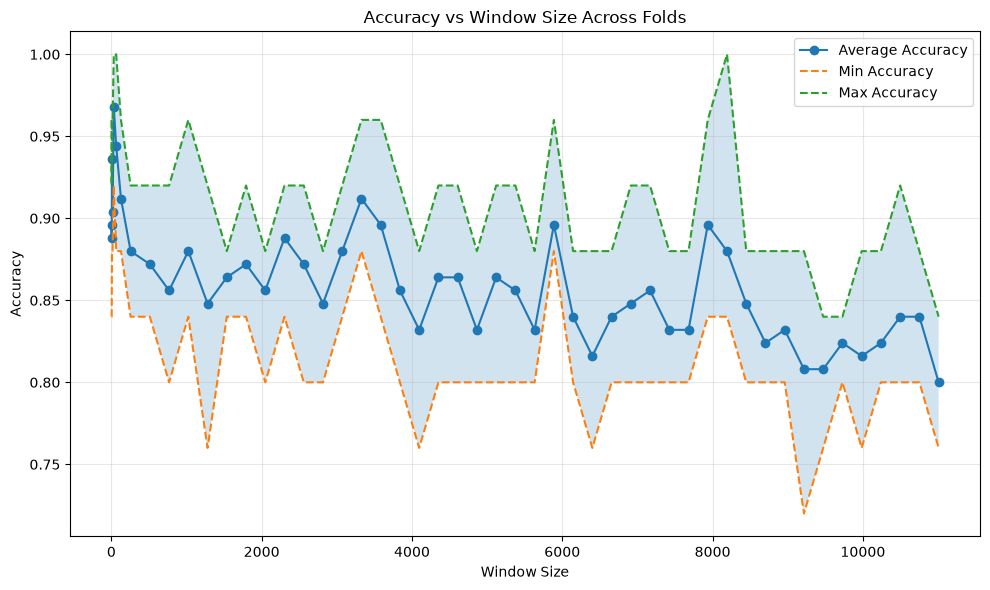

In [44]:
accuracy_summary = (
    metrics_df
    .groupby("window_size")["accuracy"]
    .agg(
        avg_accuracy="mean",
        min_accuracy="min",
        max_accuracy="max"
    )
    .reset_index()
    .sort_values("window_size")
)

plt.figure(figsize=(10, 6))

# Average accuracy
plt.plot(
    accuracy_summary["window_size"],
    accuracy_summary["avg_accuracy"],
    marker="o",
    label="Average Accuracy"
)

# Min / Max accuracy
plt.plot(
    accuracy_summary["window_size"],
    accuracy_summary["min_accuracy"],
    linestyle="--",
    label="Min Accuracy"
)

plt.plot(
    accuracy_summary["window_size"],
    accuracy_summary["max_accuracy"],
    linestyle="--",
    label="Max Accuracy"
)

# Shade the min-max range
plt.fill_between(
    accuracy_summary["window_size"],
    accuracy_summary["min_accuracy"],
    accuracy_summary["max_accuracy"],
    alpha=0.2
)

plt.xlabel("Window Size")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Window Size Across Folds")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [45]:
accuracy_summary.sort_values(by=["avg_accuracy", "window_size"], ascending=[False, True]).head(10)

,window_size,avg_accuracy,min_accuracy,max_accuracy
4,32,0.968,0.92,1.00
5,64,0.944,0.88,1.00
2,8,0.936,0.88,0.96
6,128,0.912,0.88,0.96
19,3328,0.912,0.88,0.96
3,16,0.904,0.88,0.96
0,2,0.896,0.84,0.96
20,3584,0.896,0.84,0.96
29,5888,0.896,0.88,0.96
37,7936,0.896,0.84,0.96


In [46]:
EXAMINING_WINDOW_SIZE = accuracy_summary.sort_values(
    by=["avg_accuracy", "window_size"],
    ascending=[False, True]
).iloc[0]["window_size"]
EXAMINING_WINDOW_SIZE

np.float64(32.0)

In [47]:
metrics_df[metrics_df["window_size"] == EXAMINING_WINDOW_SIZE]
# metrics_df[metrics_df["window_size"] == 100]

,accuracy,iot_device_count,non_iot_device_count,false_positive_count,false_negative_count,false_positive,false_negative,misclassified_devices,fold,window_size
20,0.92,19,6,0,2,[],"[18:b4:30:25:be:e4, 18:b7:9e:02:20:44]","[18:b4:30:25:be:e4, 18:b7:9e:02:20:44]",0,32
21,1.00,19,6,0,0,[],[],[],1,32
22,1.00,19,6,0,0,[],[],[],2,32
23,0.92,19,6,1,1,[74:2f:68:81:69:42],[18:b7:9e:02:20:44],"[74:2f:68:81:69:42, 18:b7:9e:02:20:44]",3,32
24,1.00,19,6,0,0,[],[],[],4,32


In [48]:
detail_metrics_df[(detail_metrics_df["window_size"] == EXAMINING_WINDOW_SIZE) & (detail_metrics_df["aggregated_prediction"] != detail_metrics_df["is_iot_device"])]

,eth.src,total_predictions,prediction_0,prediction_1,aggregated_prediction,is_iot_device,device_type,vendor,fold,window_size
6,18:b4:30:25:be:e4,4,3,1,0,1,smoke alarm,Nest,0,32
7,18:b7:9e:02:20:44,1688,875,813,0,1,smart speaker,Invoxia,0,32
7,18:b7:9e:02:20:44,1746,909,837,0,1,smart speaker,Invoxia,3,32
14,74:2f:68:81:69:42,357,164,193,1,0,NaN,NaN,3,32


In [49]:
detail_metrics_df[(detail_metrics_df["window_size"] == EXAMINING_WINDOW_SIZE) & (detail_metrics_df["fold"] == 3)]

,eth.src,total_predictions,prediction_0,prediction_1,aggregated_prediction,is_iot_device,device_type,vendor,fold,window_size
0,00:16:6c:ab:6b:88,2700,49,2651,1,1,camera,Samsung,3,32
1,00:24:e4:11:18:a8,2700,27,2673,1,1,baby monitor,Withings,3,32
2,00:24:e4:1b:6f:96,4,1,3,1,1,smart scale,Withings,3,32
3,00:24:e4:20:28:c6,1629,8,1621,1,1,sleep sensor,Withings,3,32
4,00:62:6e:51:27:2e,2625,49,2576,1,1,camera,Insteon,3,32
5,08:21:ef:3b:fc:e3,644,491,153,0,0,NaN,NaN,3,32
6,18:b4:30:25:be:e4,4,0,4,1,1,smoke alarm,Nest,3,32
7,18:b7:9e:02:20:44,1746,909,837,0,1,smart speaker,Invoxia,3,32
8,30:8c:fb:2f:e4:b2,2700,9,2691,1,1,camera,Dropcam,3,32
9,40:f3:08:ff:1e:da,202,135,67,0,0,NaN,NaN,3,32


- Out of the folds that achieve the best accuracy, these four devices are usually misclassified `[00:24:e4:1b:6f:96, 18:b4:30:25:be:e4, 74:6a:89:00:2e:25]`

In [50]:
# misclassfied_devices = ["08:21:ef:3b:fc:e3", "b4:ce:f6:a7:a3:c2","40:f3:08:ff:1e:da", "d0:a6:37:df:a1:e1"]
# for mac in misclassfied_devices:
#     print(f"mac: {mac}, device_name: {device_dict_1[mac]["device_name"]}, is_iot_device: {device_dict_1[mac]["is_iot_device"]}, vendor: {device_dict_1[mac]["vendor"]}")

In [51]:
# features_window_EXAMINING_WINDOW_SIZE = build_feature(raw_df=process_df, device_to_be_include=device_to_be_include, window=EXAMINING_WINDOW_SIZE)
# data_df_EXAMINING_WINDOW_SIZE = label_features(features=features_window_EXAMINING_WINDOW_SIZE, device_mapping=device_dict_1)
# training_and_validation_folds_EXAMINING_WINDOW_SIZE = device_capture_repeated_split(
#     df=data_df_EXAMINING_WINDOW_SIZE,
#     list_of_devices_to_be_classified=list_of_devices_to_be_classified,
#     n_splits=KPLITS,
#     random_state=RANDOM_STATE
# )

- Examining the errors

In [52]:
# TARGET_DEVICES = misclassfied_devices


# def fit_current_model(
#     train_df,
#     val_df,
#     feature_columns,
#     random_state=RANDOM_STATE,
# ):
#     """Fit the same undersampling + scaling + decision-tree pipeline."""
#     X_train = train_df[feature_columns]
#     y_train = train_df[LABEL_COLUMN]
#     X_val = val_df[feature_columns]

#     sampler = create_under_sampler(random_seed=random_state)
#     X_train_resampled, y_train_resampled = sampler.fit_resample(
#         X_train,
#         y_train,
#     )

#     scaler = StandardScaler()
#     X_train_scaled = scaler.fit_transform(X_train_resampled)
#     X_val_scaled = scaler.transform(X_val)

#     model = create_decision_tree(random_seed=random_state)
#     model.fit(X_train_scaled, y_train_resampled)

#     predictions = model.predict(X_val_scaled)
#     positive_class_index = list(model.classes_).index(1)
#     probabilities = model.predict_proba(X_val_scaled)[:, positive_class_index]

#     return predictions, probabilities, model, scaler


# def run_fold_predictions(
#     data,
#     folds,
#     feature_columns,
# ):
#     prediction_parts = []
#     fitted_objects = []

#     for fold in folds:
#         fold_number = fold["fold"]

#         train_df = data.iloc[fold["train_iloc"]].copy()
#         val_df = data.iloc[fold["val_iloc"]].copy()

#         predictions, probabilities, model, scaler = fit_current_model(
#             train_df=train_df,
#             val_df=val_df,
#             feature_columns=feature_columns,
#         )

#         val_df["fold"] = fold_number
#         val_df["prediction_each_window"] = predictions
#         val_df["iot_probability"] = probabilities
#         val_df["is_active"] = val_df[feature_columns].sum(axis=1) > 0
#         val_df["is_correct"] = (
#             val_df["prediction_each_window"] == val_df[LABEL_COLUMN]
#         )

#         prediction_parts.append(val_df)

#         fitted_objects.append(
#             {
#                 "fold": fold_number,
#                 "model": model,
#                 "scaler": scaler,
#                 "train_df": train_df,
#             }
#         )

#     return (
#         pd.concat(prediction_parts, ignore_index=True),
#         fitted_objects,
#     )


# predictions_EXAMINING_WINDOW_SIZE, fitted_models_EXAMINING_WINDOW_SIZE = run_fold_predictions(
#     data=data_df_EXAMINING_WINDOW_SIZE,
#     folds=training_and_validation_folds_EXAMINING_WINDOW_SIZE,
#     feature_columns=FEATURE_COLUMNS,
# )

# predictions_EXAMINING_WINDOW_SIZE.head()

In [53]:
# active_inactive_diagnostic = (
#     predictions_EXAMINING_WINDOW_SIZE[
#         predictions_EXAMINING_WINDOW_SIZE["eth.src"].isin(TARGET_DEVICES)
#     ]
#     .groupby(
#         [
#             "fold",
#             "eth.src",
#             "capture_id",
#             LABEL_COLUMN,
#             "is_active",
#         ],
#         observed=True,
#         as_index=False,
#     )
#     .agg(
#         windows=("prediction_each_window", "size"),
#         predicted_iot=("prediction_each_window", "sum"),
#         predicted_iot_rate=("prediction_each_window", "mean"),
#         mean_iot_probability=("iot_probability", "mean"),
#         accuracy=("is_correct", "mean"),
#         packet_count=("packet_count", "sum"),
#         total_bytes=("total_bytes", "sum"),
#     )
# )

# active_inactive_diagnostic["device_name"] = (
#     active_inactive_diagnostic["eth.src"]
#     .map(lambda mac: device_dict_1[mac]["device_name"])
# )

In [54]:
# active_inactive_diagnostic[
#     [
#         "fold",
#         "eth.src",
#         "device_name",
#         "capture_id",
#         "is_active",
#         "windows",
#         "predicted_iot",
#         "predicted_iot_rate",
#         "mean_iot_probability",
#         "accuracy",
#     ]
# ].sort_values(
#     ["is_active", "eth.src", "fold"]
# )

In [55]:
# def plot_device_timeline(
#     prediction_df,
#     mac,
#     fold_number=0,
# ):
#     device_df = (
#         prediction_df[
#             (prediction_df["eth.src"] == mac)
#             & (prediction_df["fold"] == fold_number)
#         ]
#         .sort_values("window")
#         .copy()
#     )

#     if device_df.empty:
#         print(f"No observations for {mac} in fold {fold_number}")
#         return

#     device_name = device_dict_1[mac]["device_name"]
#     capture_ids = device_df["capture_id"].unique()

#     fig, axes = plt.subplots(
#         3,
#         1,
#         figsize=(14, 9),
#         sharex=True,
#     )

#     axes[0].step(
#         device_df["window"],
#         device_df["packet_count"],
#         where="mid",
#     )
#     axes[0].set_ylabel("Packet count")

#     axes[1].step(
#         device_df["window"],
#         device_df["total_bytes"],
#         where="mid",
#         color="tab:orange",
#     )
#     axes[1].set_ylabel("Total bytes")

#     axes[2].plot(
#         device_df["window"],
#         device_df["iot_probability"],
#         marker=".",
#         linestyle="-",
#         alpha=0.8,
#     )
#     axes[2].axhline(
#         0.5,
#         color="red",
#         linestyle="--",
#         label="Decision threshold",
#     )
#     axes[2].set_ylabel("IoT probability")
#     axes[2].set_xlabel(f"{EXAMINING_WINDOW_SIZE}-second window")
#     axes[2].set_ylim(-0.05, 1.05)
#     axes[2].legend()

#     incorrect = device_df[~device_df["is_correct"]]

#     axes[2].scatter(
#         incorrect["window"],
#         incorrect["iot_probability"],
#         color="red",
#         marker="x",
#         s=50,
#         label="Incorrect",
#     )

#     fig.suptitle(
#         f"{device_name} — fold {fold_number} — "
#         f"capture {', '.join(map(str, capture_ids))}"
#     )
#     plt.tight_layout()
#     plt.show()


# for device_mac in TARGET_DEVICES:
#     for fold_num in range(KPLITS):
#         plot_device_timeline(
#             predictions_EXAMINING_WINDOW_SIZE,
#             mac=device_mac,
#             fold_number=fold_num,
#         )

In [56]:
# activity_boundaries = (
#     predictions_EXAMINING_WINDOW_SIZE[
#         predictions_EXAMINING_WINDOW_SIZE["is_active"]
#         & predictions_EXAMINING_WINDOW_SIZE["eth.src"].isin(TARGET_DEVICES)
#     ]
#     .groupby(
#         ["fold", "eth.src", "capture_id"],
#         observed=True,
#         as_index=False,
#     )
#     .agg(
#         first_active_window=("window", "min"),
#         last_active_window=("window", "max"),
#         active_windows=("window", "size"),
#     )
# )

# activity_boundaries["first_active_second"] = (
#     activity_boundaries["first_active_window"] * EXAMINING_WINDOW_SIZE
# )

# activity_boundaries["last_active_second"] = (
#     activity_boundaries["last_active_window"] * EXAMINING_WINDOW_SIZE
# )

# activity_boundaries

In [57]:
# def build_device_aggregation_table(
#     prediction_df,
#     minimum_active_windows=3,
# ):
#     rows = []

#     group_columns = [
#         "fold",
#         "eth.src",
#         "capture_id",
#         LABEL_COLUMN,
#     ]

#     for keys, group in prediction_df.groupby(
#         group_columns,
#         observed=True,
#     ):
#         fold_number, mac, capture_id, true_label = keys
#         active = group[group["is_active"]]

#         all_window_majority = int(
#             group["prediction_each_window"].mean() >= 0.5
#         )

#         all_probability_mean = int(
#             group["iot_probability"].mean() >= 0.5
#         )

#         if active.empty:
#             active_majority = np.nan
#             active_probability_mean = np.nan
#             traffic_weighted_probability = np.nan
#         else:
#             active_majority = int(
#                 active["prediction_each_window"].mean() >= 0.5
#             )

#             active_probability_mean = int(
#                 active["iot_probability"].mean() >= 0.5
#             )

#             weights = active["total_bytes"].to_numpy(dtype=float)

#             if weights.sum() > 0:
#                 weighted_probability = np.average(
#                     active["iot_probability"],
#                     weights=weights,
#                 )
#             else:
#                 weighted_probability = active[
#                     "iot_probability"
#                 ].mean()

#             traffic_weighted_probability = int(
#                 weighted_probability >= 0.5
#             )

#         if len(active) >= minimum_active_windows:
#             minimum_evidence_prediction = active_probability_mean
#         else:
#             minimum_evidence_prediction = np.nan

#         rows.append(
#             {
#                 "fold": fold_number,
#                 "eth.src": mac,
#                 "capture_id": capture_id,
#                 LABEL_COLUMN: true_label,
#                 "total_windows": len(group),
#                 "active_windows": len(active),
#                 "all_window_majority": all_window_majority,
#                 "all_probability_mean": all_probability_mean,
#                 "active_window_majority": active_majority,
#                 "active_probability_mean": active_probability_mean,
#                 "traffic_weighted_probability": (
#                     traffic_weighted_probability
#                 ),
#                 "minimum_evidence_prediction": (
#                     minimum_evidence_prediction
#                 ),
#             }
#         )

#     return pd.DataFrame(rows)


# aggregation_EXAMINING_WINDOW_SIZE = build_device_aggregation_table(
#     predictions_EXAMINING_WINDOW_SIZE,
#     minimum_active_windows=3,
# )

# aggregation_EXAMINING_WINDOW_SIZE["device_name"] = (
#     aggregation_EXAMINING_WINDOW_SIZE["eth.src"]
#     .map(lambda mac: device_dict_1[mac]["device_name"])
# )

# aggregation_EXAMINING_WINDOW_SIZE[
#     aggregation_EXAMINING_WINDOW_SIZE["eth.src"].isin(TARGET_DEVICES)
# ].sort_values(
#     ["eth.src", "fold"]
# )

In [58]:
# aggregation_methods = [
#     "all_window_majority",
#     "all_probability_mean",
#     "active_window_majority",
#     "active_probability_mean",
#     "traffic_weighted_probability",
#     "minimum_evidence_prediction",
# ]

# aggregation_results = []

# for method in aggregation_methods:
#     eligible = aggregation_EXAMINING_WINDOW_SIZE[method].notna()

#     aggregation_results.append(
#         {
#             "method": method,
#             "eligible_device_captures": int(eligible.sum()),
#             "coverage": eligible.mean(),
#             "accuracy": accuracy_score(
#                 aggregation_EXAMINING_WINDOW_SIZE.loc[eligible, LABEL_COLUMN],
#                 aggregation_EXAMINING_WINDOW_SIZE.loc[eligible, method].astype(int),
#             ),
#             "balanced_accuracy": balanced_accuracy_score(
#                 aggregation_EXAMINING_WINDOW_SIZE.loc[eligible, LABEL_COLUMN],
#                 aggregation_EXAMINING_WINDOW_SIZE.loc[eligible, method].astype(int),
#             ),
#         }
#     )

# pd.DataFrame(aggregation_results).sort_values(
#     "balanced_accuracy",
#     ascending=False,
# )

In [59]:
# zero_vector_results = []

# zero_vector = pd.DataFrame(
#     [[0, 0]],
#     columns=FEATURE_COLUMNS,
# )

# for fitted in fitted_models_EXAMINING_WINDOW_SIZE:
#     scaled_zero = fitted["scaler"].transform(zero_vector)

#     prediction = fitted["model"].predict(scaled_zero)[0]
#     positive_index = list(
#         fitted["model"].classes_
#     ).index(1)

#     probability = fitted["model"].predict_proba(
#         scaled_zero
#     )[0, positive_index]

#     zero_vector_results.append(
#         {
#             "fold": fitted["fold"],
#             "zero_vector_prediction": prediction,
#             "zero_vector_iot_probability": probability,
#         }
#     )

# pd.DataFrame(zero_vector_results)

In [60]:
# zero_rows = data_df_EXAMINING_WINDOW_SIZE[
#     (data_df_EXAMINING_WINDOW_SIZE["packet_count"] == 0)
#     & (data_df_EXAMINING_WINDOW_SIZE["total_bytes"] == 0)
# ].copy()

# zero_rows_by_class = (
#     zero_rows.groupby(
#         LABEL_COLUMN,
#         observed=True,
#     )
#     .size()
#     .rename("zero_windows")
#     .reset_index()
# )

# display(zero_rows_by_class)

# zero_rows_by_device = (
#     data_df_EXAMINING_WINDOW_SIZE.assign(
#         is_zero=lambda df: (
#             (df["packet_count"] == 0)
#             & (df["total_bytes"] == 0)
#         )
#     )
#     .groupby(
#         ["eth.src", LABEL_COLUMN],
#         observed=True,
#         as_index=False,
#     )
#     .agg(
#         total_windows=("window", "size"),
#         zero_windows=("is_zero", "sum"),
#     )
# )

# zero_rows_by_device["zero_fraction"] = (
#     zero_rows_by_device["zero_windows"]
#     / zero_rows_by_device["total_windows"]
# )

# zero_rows_by_device[
#     zero_rows_by_device["eth.src"].isin(TARGET_DEVICES)
# ]

In [61]:
# feature_collision_counts = (
#     data_df_EXAMINING_WINDOW_SIZE
#     .groupby(
#         FEATURE_COLUMNS + [LABEL_COLUMN],
#         observed=True,
#     )
#     .size()
#     .unstack(
#         LABEL_COLUMN,
#         fill_value=0,
#     )
# )

# for class_label in [0, 1]:
#     if class_label not in feature_collision_counts.columns:
#         feature_collision_counts[class_label] = 0

# conflicting_vectors = feature_collision_counts[
#     (feature_collision_counts[0] > 0)
#     & (feature_collision_counts[1] > 0)
# ].copy()

# conflicting_vectors["rows_in_collision"] = (
#     conflicting_vectors[0]
#     + conflicting_vectors[1]
# )

# conflicting_vectors.sort_values(
#     "rows_in_collision",
#     ascending=False,
# ).head(20)

In [62]:
# plot_df = data_df_EXAMINING_WINDOW_SIZE.copy()

# plot_df["log_packet_count"] = np.log1p(
#     plot_df["packet_count"]
# )
# plot_df["log_total_bytes"] = np.log1p(
#     plot_df["total_bytes"]
# )
# plot_df["class_name"] = plot_df[LABEL_COLUMN].map(
#     {0: "Non-IoT", 1: "IoT"}
# )

# if len(plot_df) > 40_000:
#     plot_sample = plot_df.sample(
#         40_000,
#         random_state=RANDOM_STATE,
#     )
# else:
#     plot_sample = plot_df

# plt.figure(figsize=(11, 8))

# sns.scatterplot(
#     data=plot_sample,
#     x="log_packet_count",
#     y="log_total_bytes",
#     hue="class_name",
#     alpha=0.25,
#     s=20,
# )

# target_points = plot_df[
#     plot_df["eth.src"].isin(TARGET_DEVICES)
#     & (plot_df["packet_count"] > 0)
# ]

# # sns.scatterplot(
# #     data=target_points,
# #     x="log_packet_count",
# #     y="log_total_bytes",
# #     color="red",
# #     marker="X",
# #     s=80,
# #     label="Four examined devices",
# # )

# plt.title(f"Feature overlap at an {EXAMINING_WINDOW_SIZE}-second window")
# plt.xlabel("log(1 + packet count)")
# plt.ylabel("log(1 + total bytes)")
# plt.tight_layout()
# plt.show()

# Insight
- The problem: Given data trace for the whole day of a device, can i predict if that device is an IoT or non-IoT?
- Data preprocessing steps:
    - Any devices that only have one trace file is dropped because they can't be splitted into training and validation fold
- Training and validation fold is splitted using Leave-One-Out approach
    - In each fold, for each device, pick one trace file for the validation, the rest will be placed in the training folds

- The reason for the misclassification is that:
    - Vector `(0,0)` get classfied as `0`, and this vector dominate the features belonging to these devices
        - Even though `(0,0)` associated with label 1 more (5000 vs 2000), `RandomUnderSampler` actually remove that dominant. <mark>What happen if we remove it?</mark>
            - Okay, without `RandomUnderSampler`, there is an imbalanced dataset, which make the model predict everything to be IoT. What if we add `classweight` to penalize wrong prediction on non-IoT class heavier?
                - After adding classweight, the same misclassification still happening, what if we drop those device?
                    - After dropping those devices, the accuracy increase significantly. Out of 5 folds, we usually get 3 folds with maximum accuracy, the rest usually get misclassified on `[74:c6:3b:29:d7:1d, e0:76:d0:33:bb:85]`
                - Okay, if we don't drop it, then what is the solution? <mark> can we extend the window so that the number of inactive window get smaller in those devices? Let's try</mark>
                    - I tried up to 11 hours window size. Something interesting appears. The accuracy does increase but we haven't reached 100%.
                    - I thought about increasing the window size more, but it would be irrational. Since we evaluate the device based on the trace of one day worth of trace, if our window size is about 12 hours, then we only have 2 sample for training and validation which is no different than random decision.
    - Nest Protect has a different problem. Its active window are still being predicted as non-IoT. <mark>We might need to add features?</mark>
        - We might need more information to be able to tell it apart. <mark>More features?</mark>
            - We have been only recording outgoing volume, what about incoming? <mark> Try that and it doesn't improve</mark>

# Meeting Note
## Do another sampler method
## We can skip inactive window while training and validating 
- <mark> Trying this first</mark>
- First observation:
    - Optimal window size: 2400, accuracy: 91%
    - The misclassified devices are all false positive, which seems like an imbalanced dataset
    - The window size vs performance plot looks messy, looks pretty much like random -> <mark>might be mixed signal between iot device and non-iot device?</mark>
```bash
mac: 08:21:ef:3b:fc:e3, device_name: Samsung Galaxy Tab, is_iot_device: 0, vendor: nan
mac: b4:ce:f6:a7:a3:c2, device_name: Android Phone, is_iot_device: 0, vendor: nan
mac: 40:f3:08:ff:1e:da, device_name: Android Phone, is_iot_device: 0, vendor: nan
mac: d0:a6:37:df:a1:e1, device_name: IPhone, is_iot_device: 0, vendor: nan
```
- Is it because of camera being in the dataset?
    - Looks like it is, when I drop camera from the dataset, the model reach it peaks at `100 seconds window`
        - It got 100% accuracy in three folds. One fold, it misclassifies `b4:ce:f6:a7:a3:c2`, and `74:6a:89:00:2e:25` for the others.
            - Reason: [Validation detail](./imgs/50-50-decision.png)
                - For `b4:ce:f6:a7:a3:c2`, the model is 50/50 on this decision
                - For `74:6a:89:00:2e:25`, same issue we had initially, this produces too less window for us to vote efficiently
    - Also looking at the scatter plot for this window, the data looks much more separable [Distribution Plots](./imgs/100s-window-distribution-plot.png)
- What if we also drop the gateway?
    - We drop it and got 100% accuracy!! for 120 seconds window
- What if we drop gateway and keep camera?
    - Some devices can not be classified correctly because of following reasons ([40s window dropping gateway performance](./imgs/40s-window-drop-gateway.png)):
        - 50/50 scenario
        - Some IoT devices (blood pressure) has too small number of active windows to be considered for majority voting
- Now that we know the full labels of the dataset? What if we rerun the experiment?
    - For some reason, the list of devices mentioned in the paper cannot be found in the dataset
## Another feature can be last inactive time
## May be model the labels into: non-IoT, IoT, and resource-constraint IoT
## Look into graph model kind of thing

# Additional Analysis

In [63]:
# debug_device_list = camera_devices.copy()
# for mac in device_dict_1:
#     if device_dict_1[mac]["is_iot_device"] == 0 and mac != "14:cc:20:51:33:ea":
#         debug_device_list.append(mac)
# debug_features = build_feature(raw_df=process_df, device_to_be_include=debug_device_list, window=100)
# camera_and_non_iot_ft = label_features(features=debug_features, device_mapping=device_dict_1)

In [64]:
# plot_df = camera_and_non_iot_ft.copy()

# plot_df["log_packet_count"] = np.log1p(
#     plot_df["packet_count"]
# )
# plot_df["log_total_bytes"] = np.log1p(
#     plot_df["total_bytes"]
# )
# plot_df["class_name"] = plot_df[LABEL_COLUMN].map(
#     {0: "Non-IoT", 1: "IoT"}
# )

# if len(plot_df) > 40_000:
#     plot_sample = plot_df.sample(
#         40_000,
#         random_state=RANDOM_STATE,
#     )
# else:
#     plot_sample = plot_df

# plt.figure(figsize=(11, 8))

# sns.scatterplot(
#     data=plot_sample,
#     x="log_packet_count",
#     y="log_total_bytes",
#     hue="class_name",
#     alpha=0.25,
#     s=20,
# )

# target_points = plot_df[
#     plot_df["eth.src"].isin(TARGET_DEVICES)
#     & (plot_df["packet_count"] > 0)
# ]

# plt.title(f"Feature overlap at an {EXAMINING_WINDOW_SIZE}-second window")
# plt.xlabel("log(1 + packet count)")
# plt.ylabel("log(1 + total bytes)")
# plt.tight_layout()
# plt.show()